# Hürlimann: how formulas (2.3) and (2.4) work

Continuing from `hurlimann_2_1.ipynb` and `hurlimann_2_2.ipynb`. Using the loss ratios $m_k$ from (2.1) and the burning cost from (2.2), Hürlimann defines the **loss ratio payout factor** and the **loss ratio reserve factor**:

$$p_i = \frac{V_i \sum_{k=1}^{n-i+1} m_k}{E[U_i^{BC}]} = \frac{\sum_{k=1}^{n-i+1} m_k}{\sum_{k=1}^{n} m_k} \tag{2.3}$$

$$q_i = 1 - p_i = \frac{\sum_{k=n-i+2}^{n} m_k}{\sum_{k=1}^{n} m_k} \tag{2.4}$$

* $p_i$ is the share of origin period $i$'s expected ultimate that is paid by the end of development period $n-i+1$ (i.e. by now).
* $q_i$ is the share still unpaid.

Two things to see in the pictures:

1. **$V_i$ cancels.** Both numerator and denominator of (2.3) carry $V_i$ (the burning cost is $V_i \sum m_k$), so $p_i$ and $q_i$ depend only on the pattern $m_k$ and on where the diagonal falls, not on the size of the origin period.
2. **Choice of $i$ moves the cut point.** The pattern $m_1,\dots,m_n$ is cut after $k = n-i+1$. Left of the cut is the numerator of $p_i$, right of the cut is the numerator of $q_i$, and the total is the common denominator.

**Data are synthetic** (same invented triangle and seed as the earlier notebooks), not from the paper or an exam.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

n = 10
rng = np.random.default_rng(7)

# Synthetic inputs (assumed, same as the 2.1 / 2.2 notebooks)
V = np.round(1000 * 1.05 ** np.arange(n))
m_true = np.array([.18, .20, .14, .09, .06, .04, .03, .02, .015, .01])
S_full = np.round(V[:, None] * m_true[None, :] * rng.normal(1, 0.08, (n, n)))
i_idx, k_idx = np.indices((n, n)) + 1
observed = i_idx + k_idx <= n + 1
S = np.where(observed, S_full, np.nan)

# (2.1) loss ratios
m = np.array([S[:n-k+1, k-1].sum() / V[:n-k+1].sum() for k in range(1, n + 1)])
tot = m.sum()

# (2.3) and (2.4)
p = np.array([m[:n-i+1].sum() / tot for i in range(1, n + 1)])
q = np.array([m[n-i+1:].sum() / tot for i in range(1, n + 1)])
assert np.allclose(p + q, 1)

# Check that V_i really cancels: compute p_i the long way (2.3, first form)
BC = V * tot
p_long = np.array([V[i-1] * m[:n-i+1].sum() / BC[i-1] for i in range(1, n + 1)])
assert np.allclose(p, p_long)

pd.DataFrame({'n-i+1 (cut)': [n-i+1 for i in range(1, n+1)],
              'sum m_k, k<=cut': [m[:n-i+1].sum() for i in range(1, n+1)],
              'sum m_k, k>cut': [m[n-i+1:].sum() for i in range(1, n+1)],
              'sum all m_k': tot,
              'p_i': p.round(4), 'q_i': q.round(4)},
             index=pd.Index(range(1, n + 1), name='i')).round(4)

,n-i+1 (cut),"sum m_k, k<=cut","sum m_k, k>cut",sum all m_k,p_i,q_i
i,,,,,,
1,10,0.7623,0.0000,0.7623,1.0000,0.0000
2,9,0.7523,0.0100,0.7623,0.9869,0.0131
3,8,0.7391,0.0232,0.7623,0.9696,0.0304
4,7,0.7191,0.0432,0.7623,0.9434,0.0566
5,6,0.6915,0.0708,0.7623,0.9072,0.0928
6,5,0.6535,0.1088,0.7623,0.8573,0.1427
7,4,0.5919,0.1704,0.7623,0.7765,0.2235
8,3,0.5050,0.2573,0.7623,0.6624,0.3376
9,2,0.3702,0.3921,0.7623,0.4856,0.5144


The assertions confirm that $p_i + q_i = 1$ and that the premium-weighted form of (2.3) gives the same $p_i$ as the pure $m_k$ form, i.e. $V_i$ cancels.

## Picture 1: the pattern $m_k$, cut at the diagonal

Each panel is the same bar chart of $m_k$. Only the cut changes with $i$:

* **Blue** bars ($k \le n-i+1$): the numerator of $p_i$.
* **Orange** bars ($k > n-i+1$): the numerator of $q_i$.
* Blue + orange = $\sum_k m_k$, the common denominator.

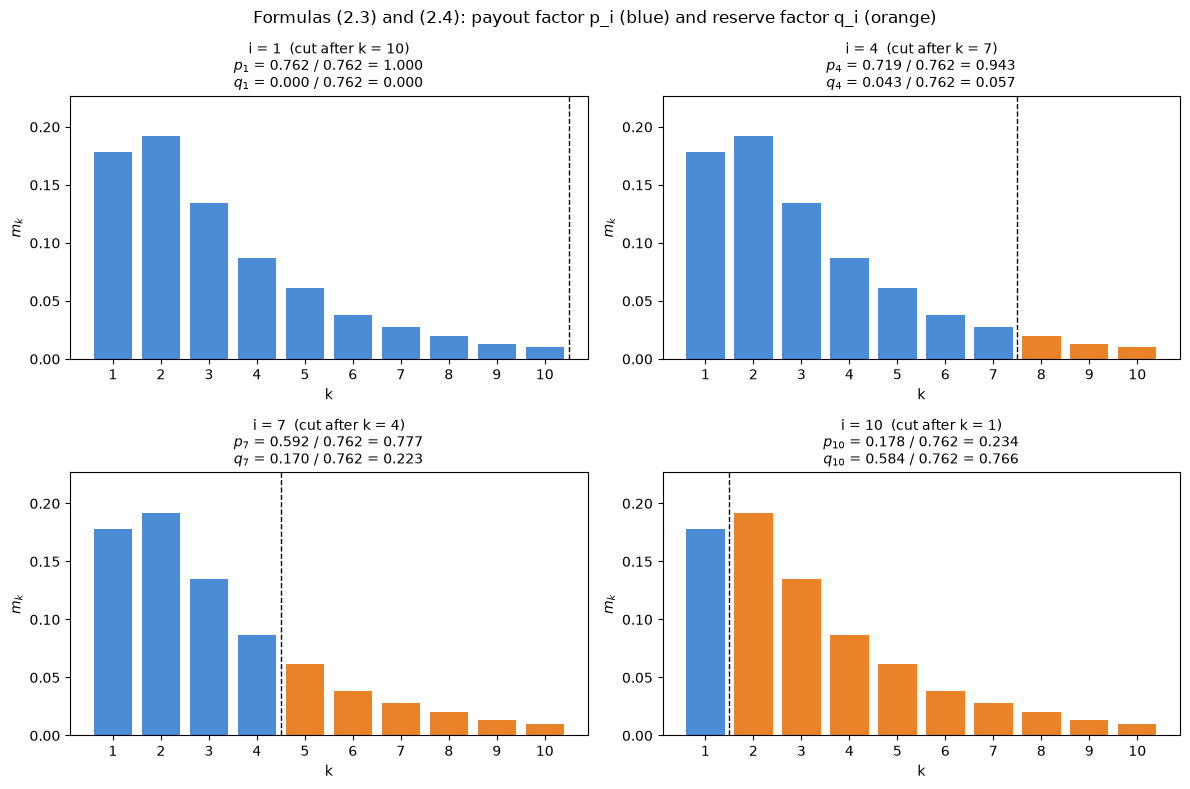

In [2]:
BLUE, ORANGE = '#4c8bd6', '#e8832a'

def draw_bars(i, ax):
    cut = n - i + 1
    k = np.arange(1, n + 1)
    ax.bar(k, m, color=[BLUE if kk <= cut else ORANGE for kk in k], width=.8)
    ax.axvline(cut + .5, color='black', ls='--', lw=1)
    a, c = m[:cut].sum(), m[cut:].sum()
    ax.set_xticks(k); ax.set_ylim(0, m.max() * 1.18)
    ax.set_xlabel('k'); ax.set_ylabel('$m_k$')
    ax.set_title(f'i = {i}  (cut after k = {cut})\n'
                 f'$p_{{{i}}}$ = {a:.3f} / {tot:.3f} = {a/tot:.3f}\n'
                 f'$q_{{{i}}}$ = {c:.3f} / {tot:.3f} = {c/tot:.3f}', fontsize=10)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, i in zip(axes.ravel(), [1, 4, 7, 10]):
    draw_bars(i, ax)
fig.suptitle('Formulas (2.3) and (2.4): payout factor p_i (blue) and reserve factor q_i (orange)', fontsize=12)
plt.tight_layout(); plt.show()

### Reading the pictures

* **i = 1** (oldest year): the cut is after $k = 10$, so everything is blue: $p_1 = 1$, $q_1 = 0$. All claims are assumed paid.
* **i = 4:** cut after $k=7$. The three small tail values are orange, so only a small share (about 6%) is still unpaid.
* **i = 7:** cut after $k=4$. The large early periods $m_1$ to $m_4$ are blue, but the long tail leaves $q_7$ around 22%.
* **i = 10** (newest year): only $m_1$ is blue, so $p_{10}$ is small (about 23%) and $q_{10}$ is large.

Because $m_k$ is front-loaded, $p_i$ rises quickly as the cut moves right.

## Picture 2: all rows as a staircase

Each row is origin period $i$, drawn as the *same* strip of $m_k$ cells (shaded by size within each row's colour), so the diagonal staircase between blue and orange is visible. The numbers on the right are $p_i$ and $q_i$. Since $V_i$ cancels, nothing in this picture depends on premium.

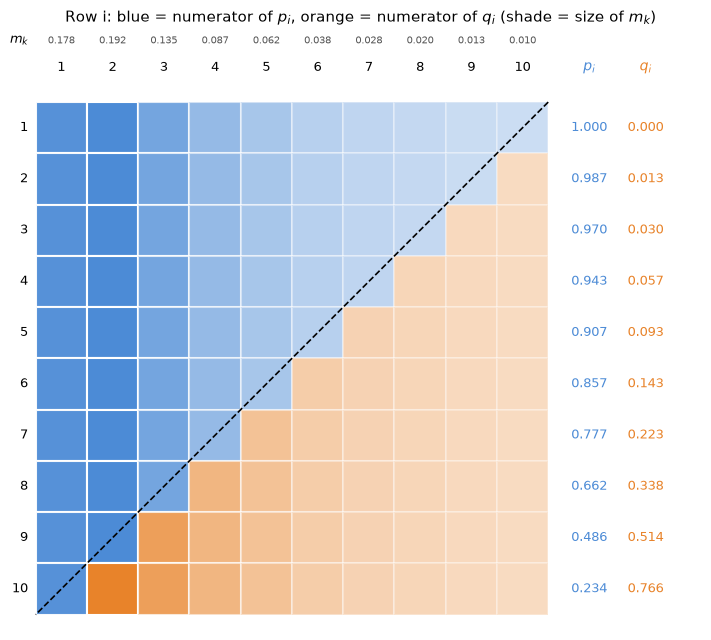

In [3]:
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.set_xlim(-.3, n + 3); ax.set_ylim(n + .3, -1.4); ax.set_aspect('equal'); ax.axis('off')

for k in range(1, n + 1):
    ax.text(k - .5, -.55, k, ha='center', va='bottom', fontsize=9)
    ax.text(k - .5, -1.1, f'{m[k-1]:.3f}', ha='center', va='bottom', fontsize=7, color='#555')
ax.text(-.15, -1.1, '$m_k$', ha='right', va='bottom', fontsize=9)
ax.text(n + .8, -.55, '$p_i$', ha='center', va='bottom', fontsize=10, fontweight='bold', color=BLUE)
ax.text(n + 1.9, -.55, '$q_i$', ha='center', va='bottom', fontsize=10, fontweight='bold', color=ORANGE)

mx = m.max()
for i in range(1, n + 1):
    cut = n - i + 1
    ax.text(-.15, i - .5, i, ha='right', va='center', fontsize=9)
    for k in range(1, n + 1):
        base = BLUE if k <= cut else ORANGE
        alpha = .25 + .75 * m[k-1] / mx                   # darker = bigger m_k
        ax.add_patch(Rectangle((k - 1, i - 1), 1, 1, fc=base, alpha=alpha, ec='white', lw=1.5))
    ax.text(n + .8, i - .5, f'{p[i-1]:.3f}', ha='center', va='center', fontsize=9, color=BLUE)
    ax.text(n + 1.9, i - .5, f'{q[i-1]:.3f}', ha='center', va='center', fontsize=9, color=ORANGE)

ax.plot([n, 0], [0, n], color='black', lw=1.2, ls='--')
ax.set_title('Row i: blue = numerator of $p_i$, orange = numerator of $q_i$ (shade = size of $m_k$)', fontsize=11)
plt.tight_layout(); plt.show()

The staircase is the same shape as the observed triangle in (2.1): blue cells are the development periods already observed for each origin period, orange cells are the unobserved lower right. So $p_i$ is "the observed part of the pattern", and $q_i$ is "the unobserved part of the pattern", each as a fraction of the whole pattern.

## Picture 3: $p_i$ and $q_i$ by origin period

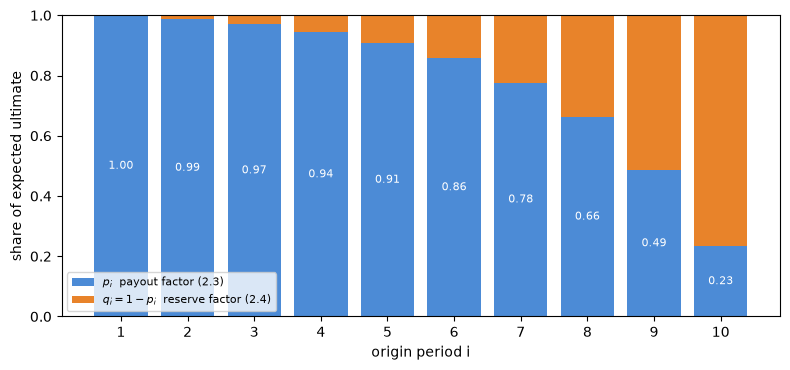

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(1, n + 1)
ax.bar(x, p, color=BLUE, label='$p_i$  payout factor (2.3)')
ax.bar(x, q, bottom=p, color=ORANGE, label='$q_i = 1 - p_i$  reserve factor (2.4)')
for xi, pi in zip(x, p):
    ax.text(xi, pi / 2, f'{pi:.2f}', ha='center', va='center', color='white', fontsize=8)
ax.set_xticks(x); ax.set_xlabel('origin period i'); ax.set_ylabel('share of expected ultimate')
ax.legend(fontsize=8, loc='lower left'); plt.tight_layout(); plt.show()

### Link to the next formulas

(2.5) grosses up the latest paid amount, $U_i^{ind} = C_{i,n-i+1}/p_i$, and (2.6) gives the reserve $R_i^{ind} = q_i U_i^{ind} = \frac{q_i}{p_i}\,C_{i,n-i+1}$. The $p_i$ and $q_i$ drawn above are exactly what those formulas use.